<a href="https://colab.research.google.com/github/Bilal-data/nyc-taxi-tip-analysis/blob/main/nyc_taxi_tip_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import seaborn as sns

taxi = sns.load_dataset("taxis")
print(taxi.shape)
print(taxi.columns.tolist())

(6433, 14)
['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']


In [2]:
taxi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

In [3]:
taxi.groupby("payment")["tip"].mean()

,tip
payment,
cash,0.000000
credit card,2.781805


In [4]:
cash = taxi[taxi["payment"] == "cash"]
print(len(cash))
print((cash["tip"] > 0).sum())

1812
0


In [5]:
card = taxi[taxi["payment"] == "credit card"]
print(len(card))

4577


In [6]:
card["tip"].describe()

,tip
count,4577.000000
mean,2.781805
std,2.488783
min,0.000000
25%,1.500000
50%,2.200000
75%,3.260000
max,33.200000


In [7]:
card = card.copy()
card["tip_pct"] = card["tip"] / card["fare"] * 100
card["tip_pct"].describe()

,tip_pct
count,4577.000000
mean,23.781563
std,11.676287
min,0.000000
25%,18.181818
50%,25.500000
75%,30.650000
max,93.333333


In [8]:
card["hour"] = card["pickup"].dt.hour
card["hour"].value_counts().sort_index()

,count
hour,
0,138
1,72
2,64
3,47
4,37
5,32
6,106
7,156
8,229


In [9]:
card.groupby("hour")["tip_pct"].agg(["count", "median"])

,count,median
hour,,
0,138,25.299261
1,72,26.909091
2,64,27.275132
3,47,23.529412
4,37,23.846154
5,32,25.050505
6,106,24.597291
7,156,26.477273
8,229,24.714286


In [10]:
card.groupby("pickup_borough")["tip_pct"].agg(["count", "median"])

,count,median
pickup_borough,,
Bronx,74,0.000000
Brooklyn,261,0.000000
Manhattan,3839,26.545455
Queens,383,21.052632


In [11]:
card.groupby("color")["tip_pct"].agg(["count", "median"])

,count,median
color,,
green,577,10.285714
yellow,4000,26.333333


In [12]:
import pandas as pd

pd.crosstab(card["pickup_borough"], card["color"])

color,green,yellow
pickup_borough,,
Bronx,62,12
Brooklyn,216,45
Manhattan,155,3684
Queens,141,242


In [13]:
card.groupby(["pickup_borough", "color"])["tip_pct"].agg(["count", "median"])

count     median
pickup_borough color                   
Bronx          green      62   0.000000
               yellow     12   0.000000
Brooklyn       green     216   0.000000
               yellow     45  21.000000
Manhattan      green     155  22.285714
               yellow   3684  26.666667
Queens         green     141  10.000000
               yellow    242  21.420330

## Findings (credit card trips only, n = 4,577)
- Cash tips are recorded as 0 in this data (1,812 cash trips, none with a tip), so cash trips were excluded.
- Typical tip: median 25.5% of the fare (mean 23.8%).
- Hour of day: median tip % stays about 24 to 27% all day. The biggest gaps appear in hours with few trips (hour 2: 64, hour 3: 47), so they are probably noise.
- Taxi color and borough are tangled together: green taxis tip much less overall (10.3% vs 26.3%), but most green trips start outside Manhattan. Inside Manhattan the gap is small (22.3% vs 26.7%); in Brooklyn and Queens it stays large.
- Limits: a sample of 6,433 trips, only 74 Bronx trips, zero-tip medians in some boroughs may be a recording issue (not verified), and trip distance and fare size were not controlled for.

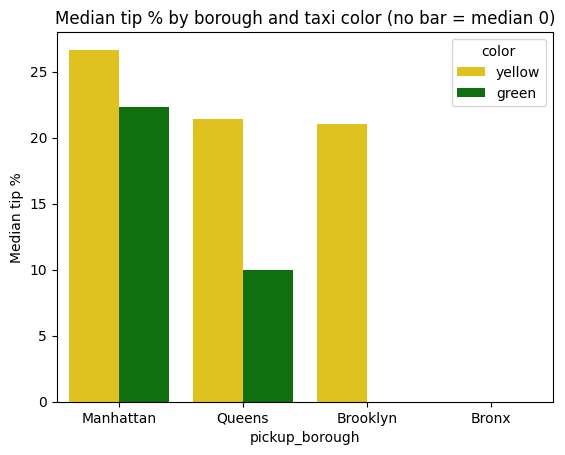

In [15]:
import matplotlib.pyplot as plt

sns.barplot(data=card, x="pickup_borough", y="tip_pct", hue="color",
            order=["Manhattan", "Queens", "Brooklyn", "Bronx"],
            palette={"yellow": "gold", "green": "green"},
            estimator="median", errorbar=None)
plt.title("Median tip % by borough and taxi color (no bar = median 0)")
plt.ylabel("Median tip %")
plt.show()